In [1]:
#import libraries 
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate,
    RandomizedSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
#load dataset
DATA_PATH = "Bengaluru_House_Data.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (13320, 9)


,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [3]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe().T)

print("\nCategorical Summary:")
display(df.describe(include="object").T)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  object 
 1   availability  13320 non-null  object 
 2   location      13319 non-null  object 
 3   size          13304 non-null  object 
 4   society       7818 non-null   object 
 5   total_sqft    13320 non-null  object 
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), object(6)
memory usage: 936.7+ KB

Missing Values:


,Missing Values
area_type,0
availability,0
location,1
size,16
society,5502
total_sqft,0
bath,73
balcony,609
price,0



Duplicate Records:
529

Statistical Summary:


,count,mean,std,min,25%,50%,75%,max
bath,13247.0,2.692610,1.341458,1.0,2.0,2.0,3.0,40.0
balcony,12711.0,1.584376,0.817263,0.0,1.0,2.0,2.0,3.0
price,13320.0,112.565627,148.971674,8.0,50.0,72.0,120.0,3600.0



Categorical Summary:


,count,unique,top,freq
area_type,13320,4,Super built-up Area,8790
availability,13320,81,Ready To Move,10581
location,13319,1305,Whitefield,540
size,13304,31,2 BHK,5199
society,7818,2688,GrrvaGr,80
total_sqft,13320,2117,1200,843


In [4]:


# Identify duplicate records
duplicate_rows = df[df.duplicated(keep=False)]

print("Total duplicate rows:", len(duplicate_rows))

# Display sample duplicate records
display(duplicate_rows.head(10))

# Check exact duplicate count
print("Exact duplicate records:", df.duplicated().sum())

Total duplicate rows: 909


,area_type,availability,location,size,society,total_sqft,bath,balcony,price
8,Super built-up Area,Ready To Move,Marathahalli,3 BHK,NaN,1310,3.0,1.0,63.25
33,Super built-up Area,Ready To Move,Raja Rajeshwari Nagar,3 BHK,GrrvaGr,1693,3.0,3.0,57.39
35,Super built-up Area,21-Dec,Kanakpura Road,2 BHK,PrarePa,700,2.0,1.0,36.00
38,Super built-up Area,Ready To Move,Chikkalasandra,3 BHK,NaN,1290,2.0,2.0,56.12
55,Super built-up Area,Ready To Move,Begur Road,2 BHK,Dhalsh,1200,2.0,2.0,44.00
83,Super built-up Area,Ready To Move,Garudachar Palya,3 BHK,NaN,1325,2.0,2.0,60.80
112,Super built-up Area,Ready To Move,Whitefield,2 BHK,Sonviik,1116,2.0,1.0,51.91
125,Built-up Area,Ready To Move,Kadugodi,2 BHK,NaN,1050,2.0,1.0,34.00
139,Super built-up Area,19-Jan,Chandra Layout,3 BHK,TiaksAa,1260,2.0,2.0,85.05
143,Super built-up Area,Ready To Move,ISRO Layout,2 BHK,NaN,1000,2.0,1.0,60.00


Exact duplicate records: 529


In [5]:
missing_analysis = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

missing_analysis = missing_analysis.sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing_analysis)

,Missing Count,Missing Percentage
society,5502,41.31
balcony,609,4.57
bath,73,0.55
size,16,0.12
location,1,0.01
area_type,0,0.00
availability,0,0.00
total_sqft,0,0.00
price,0,0.00


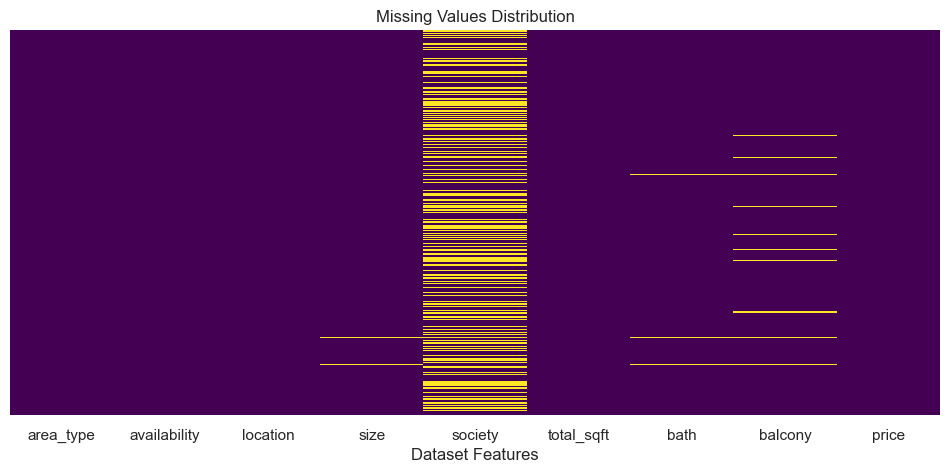

In [6]:
plt.figure(figsize=(12, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Values Distribution")
plt.xlabel("Dataset Features")
plt.show()

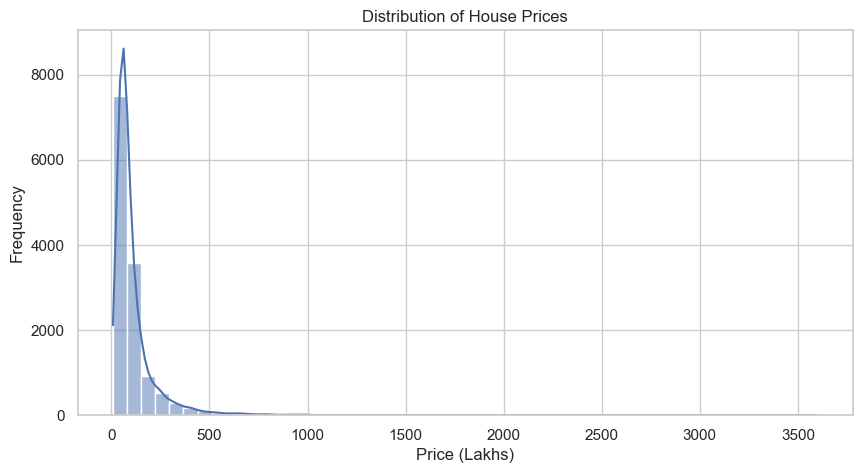

In [7]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["price"],
    bins=50,
    kde=True
)

plt.title("Distribution of House Prices")
plt.xlabel("Price (Lakhs)")
plt.ylabel("Frequency")

plt.show()

In [8]:
print("Price Statistics:")
display(df["price"].describe())

print("Price Skewness:", df["price"].skew())

Price Statistics:


count    13320.000000
mean       112.565627
std        148.971674
min          8.000000
25%         50.000000
50%         72.000000
75%        120.000000
max       3600.000000
Name: price, dtype: float64

Price Skewness: 8.06446882127325


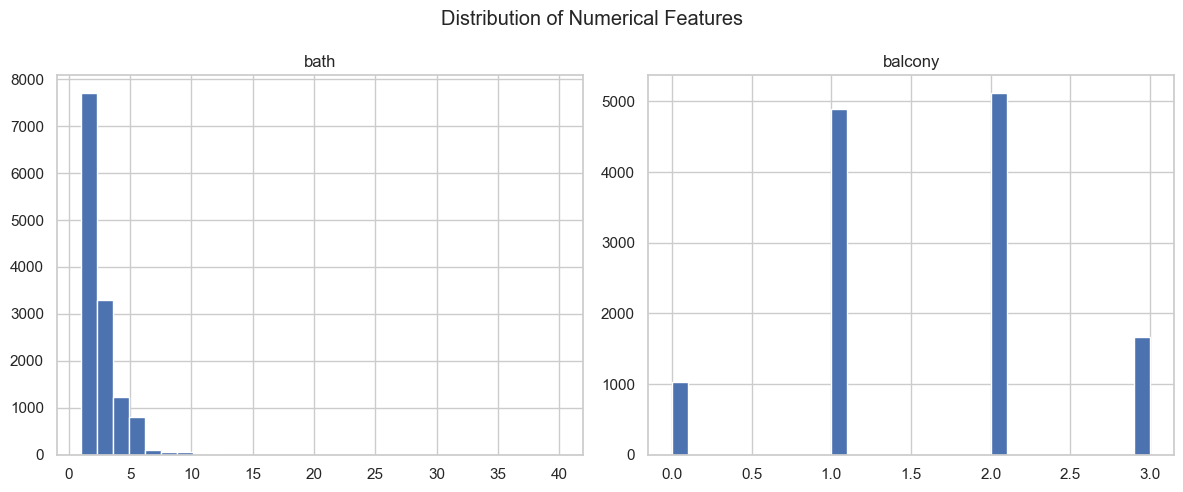

In [9]:
numerical_columns = ["bath", "balcony"]

df[numerical_columns].hist(
    figsize=(12, 5),
    bins=30
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()


Distribution of area_type


area_type
Super built-up  Area    8790
Built-up  Area          2418
Plot  Area              2025
Carpet  Area              87
Name: count, dtype: int64

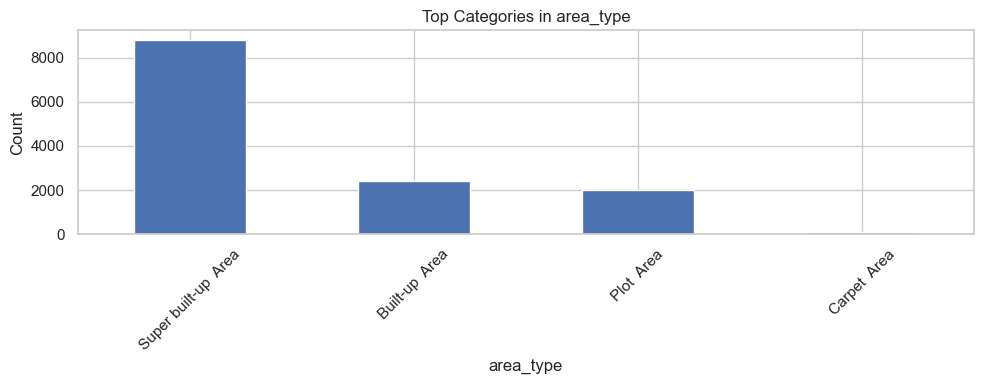


Distribution of availability


availability
Ready To Move    10581
18-Dec             307
18-May             295
18-Apr             271
18-Aug             200
19-Dec             185
18-Jul             143
18-Mar             131
18-Jun              99
20-Dec              98
21-Dec              93
19-Mar              88
18-Feb              62
18-Nov              47
18-Jan              43
Name: count, dtype: int64

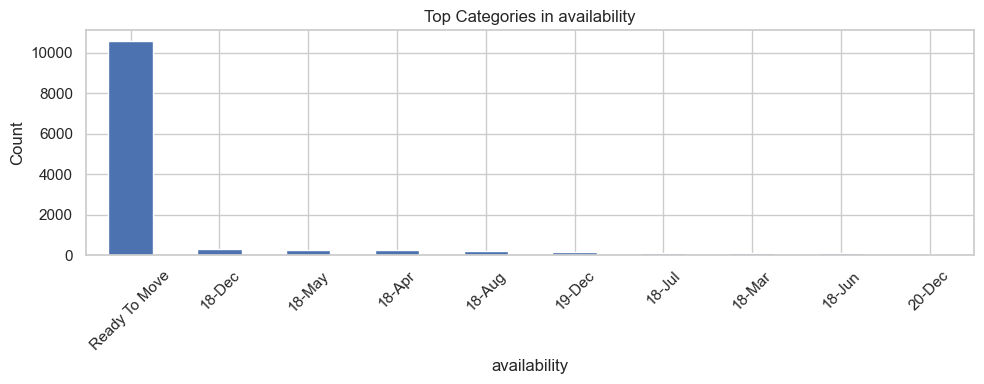

In [10]:
categorical_columns = [
    "area_type",
    "availability"
]

for column in categorical_columns:

    print(f"\nDistribution of {column}")

    display(
        df[column].value_counts().head(15)
    )

    plt.figure(figsize=(10, 4))

    df[column].value_counts().head(10).plot(
        kind="bar"
    )

    plt.title(f"Top Categories in {column}")
    plt.xlabel(column)
    plt.ylabel("Count")
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

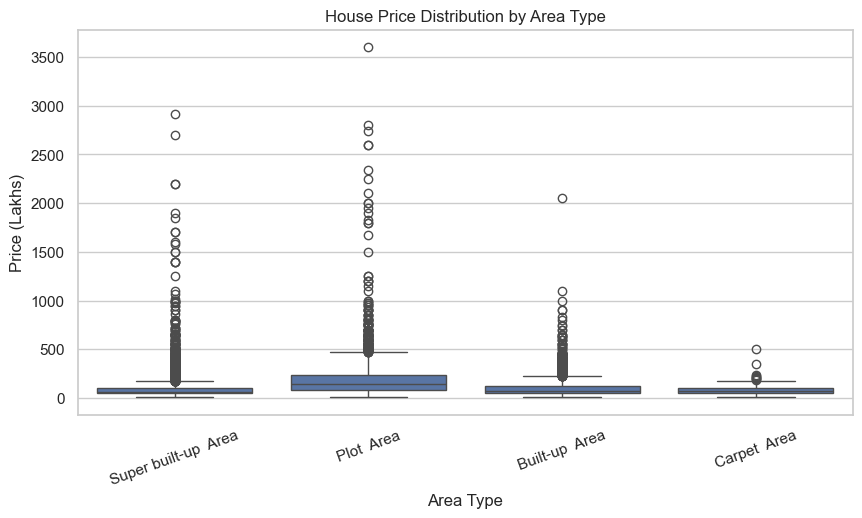

In [11]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="area_type",
    y="price"
)

plt.title("House Price Distribution by Area Type")
plt.xlabel("Area Type")
plt.ylabel("Price (Lakhs)")
plt.xticks(rotation=20)

plt.show()

In [12]:
import re
import numpy as np
import pandas as pd

def to_sqft(value):

    if pd.isna(value):
        return np.nan

    value = str(value).strip().lower().replace(",", "")

    # Handle dimensions such as 40x60
    dimensions = re.fullmatch(
        r"(\d+(?:\.\d+)?)\s*x\s*(\d+(?:\.\d+)?)",
        value
    )

    if dimensions:
        return float(dimensions.group(1)) * float(dimensions.group(2))

    # Conversion factors to square feet
    conversions = {
        "sq. meter": 10.7639,
        "sq meter": 10.7639,
        "sqm": 10.7639,
        "sq. yards": 9,
        "sq yards": 9,
        "sq. yard": 9,
        "sq yard": 9,
        "acres": 43560,
        "acre": 43560,
        "guntha": 1089,
        "cents": 435.6,
        "cent": 435.6,
        "ground": 2400
    }

    # Handle ranges
    parts = re.split(r"\s*-\s*", value)

    if len(parts) == 2:

        first = to_sqft(parts[0])
        second = to_sqft(parts[1])

        if pd.notna(first) and pd.notna(second):
            return (first + second) / 2

        return np.nan

    # Identify unit
    for unit, factor in conversions.items():

        if unit in value:

            number = re.search(r"\d+(?:\.\d+)?", value)

            if number:
                return float(number.group()) * factor

            return np.nan

    # Handle normal numerical values
    try:
        return float(value)
    except ValueError:
        return np.nan


df["total_sqft_clean"] = df["total_sqft"].apply(to_sqft)

print("Original total_sqft:")
display(df["total_sqft"].head(10))

print("\nConverted total_sqft:")
display(df[["total_sqft", "total_sqft_clean"]].head(15))

Original total_sqft:


0    1056
1    2600
2    1440
3    1521
4    1200
5    1170
6    2732
7    3300
8    1310
9    1020
Name: total_sqft, dtype: object


Converted total_sqft:


,total_sqft,total_sqft_clean
0,1056,1056.0
1,2600,2600.0
2,1440,1440.0
3,1521,1521.0
4,1200,1200.0
5,1170,1170.0
6,2732,2732.0
7,3300,3300.0
8,1310,1310.0
9,1020,1020.0


In [13]:
print("Total records:", len(df))

print(
    "Successfully converted:",
    df["total_sqft_clean"].notna().sum()
)

print(
    "Unconverted records:",
    df["total_sqft_clean"].isna().sum()
)

print("\nUnconverted values:")

display(
    df.loc[
        df["total_sqft_clean"].isna(),
        "total_sqft"
    ].value_counts().head(20)
)

Total records: 13320
Successfully converted: 13319
Unconverted records: 1

Unconverted values:


total_sqft
4125Perch    1
Name: count, dtype: int64

In [14]:
def extract_bhk(value):

    if pd.isna(value):
        return np.nan

    match = re.search(r"(\d+)", str(value))

    if match:
        return int(match.group(1))

    return np.nan


df["bhk"] = df["size"].apply(extract_bhk)

display(
    df[["size", "bhk"]].head(15)
)

,size,bhk
0,2 BHK,2.0
1,4 Bedroom,4.0
2,3 BHK,3.0
3,3 BHK,3.0
4,2 BHK,2.0
5,2 BHK,2.0
6,4 BHK,4.0
7,4 BHK,4.0
8,3 BHK,3.0
9,6 Bedroom,6.0


BHK Distribution:


bhk
1.0      656
2.0     5528
3.0     4857
4.0     1417
5.0      356
6.0      221
7.0      100
8.0       89
9.0       54
10.0      14
11.0       4
12.0       1
13.0       1
14.0       1
16.0       1
18.0       1
19.0       1
27.0       1
43.0       1
Name: count, dtype: int64

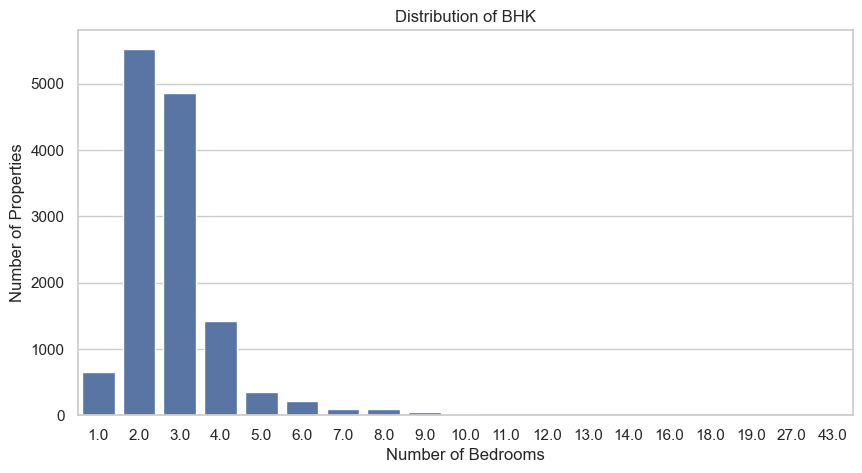

In [15]:
print("BHK Distribution:")

display(
    df["bhk"].value_counts().sort_index()
)

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="bhk",
    order=sorted(df["bhk"].dropna().unique())
)

plt.title("Distribution of BHK")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Number of Properties")

plt.show()

In [16]:
df["sqft_per_bhk"] = (
    df["total_sqft_clean"] / df["bhk"]
)

display(
    df[
        ["total_sqft_clean", "bhk", "sqft_per_bhk", "price"]
    ].head(15)
)

print("\nArea per BHK statistics:")

display(df["sqft_per_bhk"].describe())

,total_sqft_clean,bhk,sqft_per_bhk,price
0,1056.0,2.0,528.000000,39.07
1,2600.0,4.0,650.000000,120.00
2,1440.0,3.0,480.000000,62.00
3,1521.0,3.0,507.000000,95.00
4,1200.0,2.0,600.000000,51.00
5,1170.0,2.0,585.000000,38.00
6,2732.0,4.0,683.000000,204.00
7,3300.0,4.0,825.000000,600.00
8,1310.0,3.0,436.666667,63.25
9,1020.0,6.0,170.000000,370.00



Area per BHK statistics:


count     13303.000000
mean        692.460144
std        6474.567692
min           0.250000
25%         473.333333
50%         552.500000
75%         625.000000
max      653400.000000
Name: sqft_per_bhk, dtype: float64

In [17]:
model_df = df[
    [
        "area_type",
        "location",
        "total_sqft_clean",
        "bhk",
        "bath",
        "balcony",
        "price"
    ]
].copy()

print("Original shape:", df.shape)
print("Model dataset shape:", model_df.shape)

display(model_df.head())

Original shape: (13320, 12)
Model dataset shape: (13320, 7)


,area_type,location,total_sqft_clean,bhk,bath,balcony,price
0,Super built-up Area,Electronic City Phase II,1056.0,2.0,2.0,1.0,39.07
1,Plot Area,Chikka Tirupathi,2600.0,4.0,5.0,3.0,120.00
2,Built-up Area,Uttarahalli,1440.0,3.0,2.0,3.0,62.00
3,Super built-up Area,Lingadheeranahalli,1521.0,3.0,3.0,1.0,95.00
4,Super built-up Area,Kothanur,1200.0,2.0,2.0,1.0,51.00


In [18]:
print("Duplicates before removal:", model_df.duplicated().sum())

model_df = model_df.drop_duplicates().copy()

print("Duplicates after removal:", model_df.duplicated().sum())
print("Remaining records:", len(model_df))

Duplicates before removal: 691
Duplicates after removal: 0
Remaining records: 12629


In [19]:
print("Missing values before cleaning:")
display(model_df.isnull().sum())

# Target and essential feature checks
model_df = model_df.dropna(
    subset=[
        "price",
        "total_sqft_clean",
        "bhk",
        "location",
        "area_type"
    ]
).copy()

# Remove invalid or non-positive values
model_df = model_df[
    (model_df["price"] > 0) &
    (model_df["total_sqft_clean"] > 0) &
    (model_df["bhk"] > 0)
].copy()

print("\nShape after essential cleaning:", model_df.shape)

print("\nRemaining missing values:")
display(model_df.isnull().sum())

Missing values before cleaning:


area_type             0
location              1
total_sqft_clean      1
bhk                  16
bath                 72
balcony             603
price                 0
dtype: int64


Shape after essential cleaning: (12611, 7)

Remaining missing values:


area_type             0
location              0
total_sqft_clean      0
bhk                   0
bath                 56
balcony             586
price                 0
dtype: int64

In [20]:
print("Bathroom distribution:")

display(
    model_df["bath"].value_counts().sort_index()
)

print("\nProperties with more than 10 bathrooms:")

display(
    model_df[model_df["bath"] > 10]
    .sort_values("bath", ascending=False)
    .head(20)
)

Bathroom distribution:


bath
1.0      753
2.0     6441
3.0     3139
4.0     1194
5.0      517
6.0      271
7.0      102
8.0       64
9.0       41
10.0      13
11.0       3
12.0       7
13.0       3
14.0       1
15.0       1
16.0       2
18.0       1
27.0       1
40.0       1
Name: count, dtype: int64


Properties with more than 10 bathrooms:


,area_type,location,total_sqft_clean,bhk,bath,balcony,price
4684,Plot Area,Munnekollal,2400.0,43.0,40.0,0.0,660.0
1718,Super built-up Area,2Electronic City Phase II,8000.0,27.0,27.0,0.0,230.0
11559,Plot Area,1Kasavanhalli,1200.0,18.0,18.0,NaN,200.0
3379,Super built-up Area,1Hanuman Nagar,2000.0,19.0,16.0,NaN,490.0
3609,Super built-up Area,Koramangala Industrial Layout,10000.0,16.0,16.0,NaN,550.0
4916,Super built-up Area,1Channasandra,1250.0,14.0,15.0,0.0,125.0
1078,Plot Area,BTM 1st Stage,3300.0,9.0,14.0,NaN,500.0
10695,Plot Area,Electronic City,1200.0,9.0,13.0,NaN,150.0
9935,Super built-up Area,1Hoysalanagar,5425.0,13.0,13.0,0.0,275.0
13067,Plot Area,Defence Colony,7150.0,10.0,13.0,NaN,3600.0


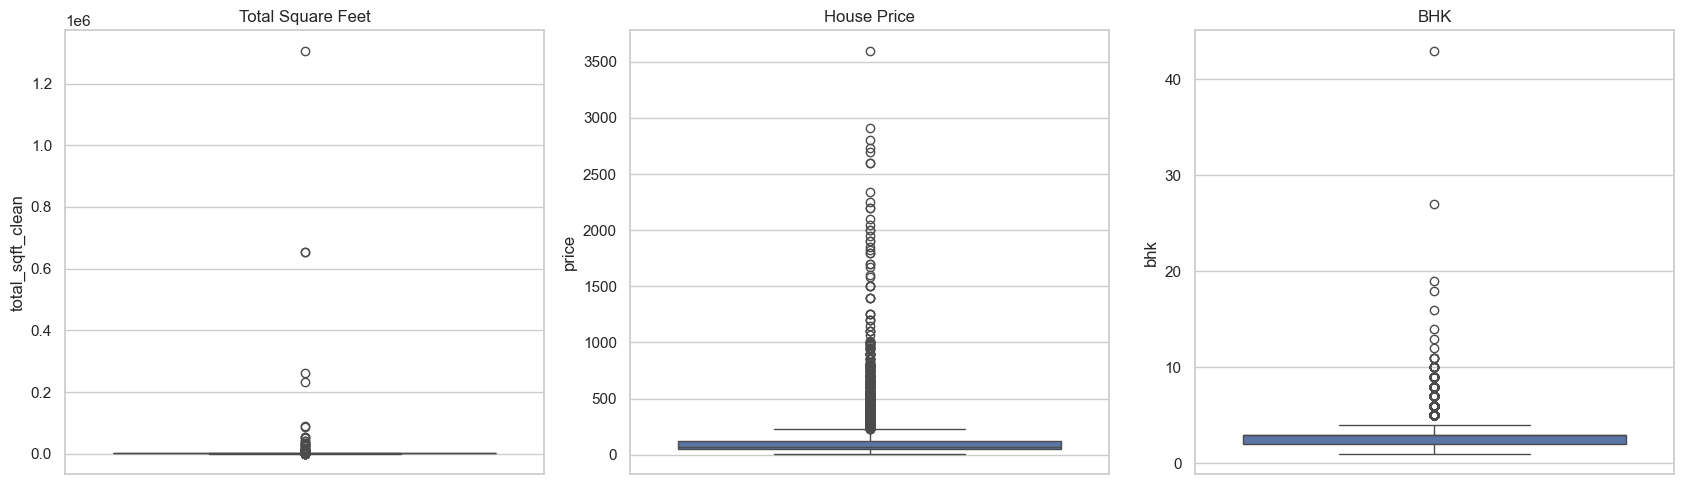

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.boxplot(y=model_df["total_sqft_clean"], ax=axes[0])
axes[0].set_title("Total Square Feet")

sns.boxplot(y=model_df["price"], ax=axes[1])
axes[1].set_title("House Price")

sns.boxplot(y=model_df["bhk"], ax=axes[2])
axes[2].set_title("BHK")

plt.tight_layout()
plt.show()

Price per square foot statistics:


count    1.261100e+04
mean     8.060449e+03
std      1.091917e+05
min      2.257423e+00
1%       2.500000e+03
5%       3.125000e+03
25%      4.299065e+03
50%      5.490196e+03
75%      7.423112e+03
95%      1.555556e+04
99%      2.419086e+04
max      1.200000e+07
Name: price_per_sqft, dtype: float64

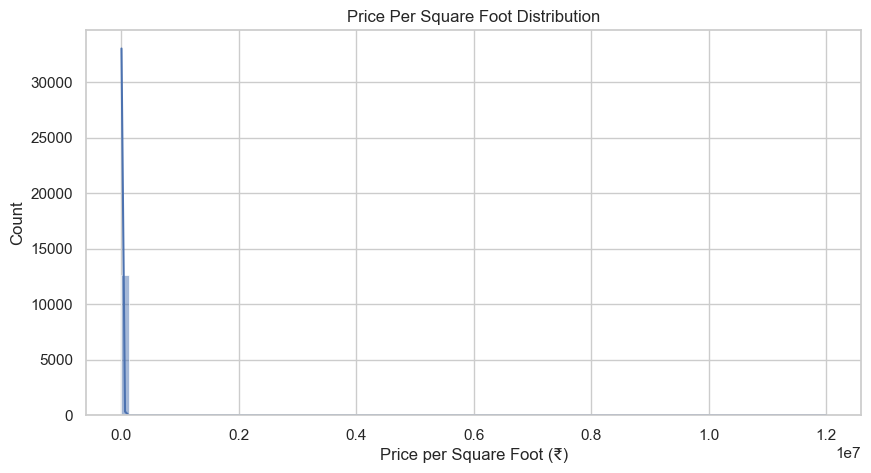

In [22]:
model_df["price_per_sqft"] = (
    model_df["price"] * 100000 /
    model_df["total_sqft_clean"]
)

print("Price per square foot statistics:")

display(
    model_df["price_per_sqft"].describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
)

plt.figure(figsize=(10, 5))

sns.histplot(
    model_df["price_per_sqft"],
    bins=100,
    kde=True
)

plt.title("Price Per Square Foot Distribution")
plt.xlabel("Price per Square Foot (₹)")

plt.show()

In [23]:
X = model_df[
    [
        "area_type",
        "location",
        "total_sqft_clean",
        "bhk",
        "bath",
        "balcony"
    ]
].copy()

y = model_df["price"].copy()

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (12611, 6)
Target shape: (12611,)


In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

print("Training target mean:", y_train.mean())
print("Testing target mean:", y_test.mean())

Training records: 10088
Testing records: 2523
Training target mean: 114.77699048374306
Testing target mean: 115.37995045580658


In [25]:
print("Training data shape:", X_train.shape)

print("\nMissing values in training features:")
display(X_train.isnull().sum())

print("\nTraining numerical feature statistics:")
display(
    X_train[
        ["total_sqft_clean", "bhk", "bath", "balcony"]
    ].describe().T
)

Training data shape: (10088, 6)

Missing values in training features:


area_type             0
location              0
total_sqft_clean      0
bhk                   0
bath                 40
balcony             456
dtype: int64


Training numerical feature statistics:


,count,mean,std,min,25%,50%,75%,max
total_sqft_clean,10088.0,1912.239385,16374.605274,5.0,1100.0,1280.0,1699.0,1306800.0
bhk,10088.0,2.808485,1.299808,1.0,2.0,3.0,3.0,43.0
bath,10048.0,2.707803,1.345771,1.0,2.0,2.0,3.0,40.0
balcony,9632.0,1.583264,0.828524,0.0,1.0,2.0,2.0,3.0


In [26]:
print("Properties with more than 10 bathrooms:")
display(
    X_train[X_train["bath"] > 10]
    .sort_values("bath", ascending=False)
)

print("\nBathroom distribution:")
display(X_train["bath"].value_counts().sort_index())

Properties with more than 10 bathrooms:


,area_type,location,total_sqft_clean,bhk,bath,balcony
4684,Plot Area,Munnekollal,2400.0,43.0,40.0,0.0
11559,Plot Area,1Kasavanhalli,1200.0,18.0,18.0,NaN
3379,Super built-up Area,1Hanuman Nagar,2000.0,19.0,16.0,NaN
3609,Super built-up Area,Koramangala Industrial Layout,10000.0,16.0,16.0,NaN
4916,Super built-up Area,1Channasandra,1250.0,14.0,15.0,0.0
1078,Plot Area,BTM 1st Stage,3300.0,9.0,14.0,NaN
10695,Plot Area,Electronic City,1200.0,9.0,13.0,NaN
6937,Plot Area,5th Block Hbr Layout,2600.0,9.0,12.0,NaN
3096,Super built-up Area,Jp nagar 8th Phase .,12000.0,10.0,12.0,NaN
7979,Super built-up Area,1 Immadihalli,6000.0,11.0,12.0,NaN



Bathroom distribution:


bath
1.0      598
2.0     5171
3.0     2500
4.0      965
5.0      412
6.0      224
7.0       73
8.0       51
9.0       31
10.0       8
11.0       2
12.0       6
13.0       1
14.0       1
15.0       1
16.0       2
18.0       1
40.0       1
Name: count, dtype: int64

In [27]:
train_diagnostics = X_train.copy()

train_diagnostics["sqft_per_bhk"] = (
    train_diagnostics["total_sqft_clean"] /
    train_diagnostics["bhk"]
)

print("Area per BHK statistics:")
display(train_diagnostics["sqft_per_bhk"].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
))

print("\nProperties with less than 300 sqft per BHK:")
display(
    train_diagnostics[
        train_diagnostics["sqft_per_bhk"] < 300
    ].head(15)
)

Area per BHK statistics:


count     10088.000000
mean        723.399425
std        7378.608072
min           0.714286
1%          139.675000
5%          262.500000
25%         475.000000
50%         555.000000
75%         628.000000
95%         906.062500
99%        1483.040000
max      653400.000000
Name: sqft_per_bhk, dtype: float64


Properties with less than 300 sqft per BHK:


,area_type,location,total_sqft_clean,bhk,bath,balcony,sqft_per_bhk
6179,Plot Area,Gangondanahalli,396.0,3.0,2.0,0.0,132.000000
12451,Plot Area,2nd Stage Nagarbhavi,1500.0,6.0,4.0,2.0,250.000000
45,Plot Area,HSR Layout,600.0,8.0,9.0,NaN,75.000000
9909,Plot Area,Uttarahalli,1200.0,6.0,6.0,2.0,200.000000
5934,Plot Area,Adityanagar,875.0,5.0,5.0,3.0,175.000000
8748,Plot Area,Mahalakshmi Layout,1135.0,8.0,4.0,1.0,141.875000
4089,Plot Area,Kanakpura Road,1080.0,5.0,6.0,3.0,216.000000
10122,Built-up Area,Kengeri Satellite Town,936.0,4.0,2.0,1.0,234.000000
6830,Plot Area,Nirman Layout,800.0,3.0,3.0,3.0,266.666667
8787,Super built-up Area,Marsur,497.0,2.0,1.0,1.0,248.500000


In [28]:
print("Top 20 properties by total square footage:")

display(
    X_train.sort_values(
        "total_sqft_clean", ascending=False
    ).head(20)
)

Top 20 properties by total square footage:


,area_type,location,total_sqft_clean,bhk,bath,balcony
1086,Plot Area,Narasapura,1306800.000,2.0,2.0,2.0
7001,Plot Area,Thyagaraja Nagar,653400.000,8.0,6.0,2.0
7607,Plot Area,Bommenahalli,653400.000,3.0,3.0,1.0
11615,Plot Area,arudi,261360.000,3.0,2.0,0.0
1019,Plot Area,Marathi Layout,231303.600,1.0,1.0,0.0
6333,Plot Area,Harohalli,91040.400,2.0,2.0,0.0
7726,Plot Area,Kanakpura Road,54885.600,1.0,1.0,0.0
1894,Plot Area,Nelamangala,52272.000,3.0,2.0,1.0
5393,Super built-up Area,Doddabommasandra,42000.000,9.0,8.0,3.0
11320,Plot Area,Arishinakunte,41382.000,1.0,1.0,0.0


In [29]:
print("Properties with more than 10 bedrooms:")

display(
    X_train[X_train["bhk"] > 10]
    .sort_values("bhk", ascending=False)
)

Properties with more than 10 bedrooms:


,area_type,location,total_sqft_clean,bhk,bath,balcony
4684,Plot Area,Munnekollal,2400.0,43.0,40.0,0.0
3379,Super built-up Area,1Hanuman Nagar,2000.0,19.0,16.0,NaN
11559,Plot Area,1Kasavanhalli,1200.0,18.0,18.0,NaN
3609,Super built-up Area,Koramangala Industrial Layout,10000.0,16.0,16.0,NaN
4916,Super built-up Area,1Channasandra,1250.0,14.0,15.0,0.0
6533,Plot Area,Mysore Road,2232.0,12.0,6.0,2.0
3853,Plot Area,1 Annasandrapalya,1200.0,11.0,6.0,3.0
7979,Super built-up Area,1 Immadihalli,6000.0,11.0,12.0,NaN
459,Super built-up Area,1 Giri Nagar,5000.0,11.0,9.0,3.0
1768,Plot Area,1 Ramamurthy Nagar,1200.0,11.0,11.0,0.0


In [30]:
print("Properties with more than 2000 sqft per BHK:")

display(
    train_diagnostics[
        train_diagnostics["sqft_per_bhk"] > 2000
    ].sort_values("sqft_per_bhk", ascending=False)
)

Properties with more than 2000 sqft per BHK:


,area_type,location,total_sqft_clean,bhk,bath,balcony,sqft_per_bhk
1086,Plot Area,Narasapura,1306800.000,2.0,2.0,2.0,653400.000000
1019,Plot Area,Marathi Layout,231303.600,1.0,1.0,0.0,231303.600000
7607,Plot Area,Bommenahalli,653400.000,3.0,3.0,1.0,217800.000000
11615,Plot Area,arudi,261360.000,3.0,2.0,0.0,87120.000000
7001,Plot Area,Thyagaraja Nagar,653400.000,8.0,6.0,2.0,81675.000000
7726,Plot Area,Kanakpura Road,54885.600,1.0,1.0,0.0,54885.600000
6333,Plot Area,Harohalli,91040.400,2.0,2.0,0.0,45520.200000
11320,Plot Area,Arishinakunte,41382.000,1.0,1.0,0.0,41382.000000
7242,Plot Area,Yelahanka,26136.000,1.0,1.0,0.0,26136.000000
1894,Plot Area,Nelamangala,52272.000,3.0,2.0,1.0,17424.000000


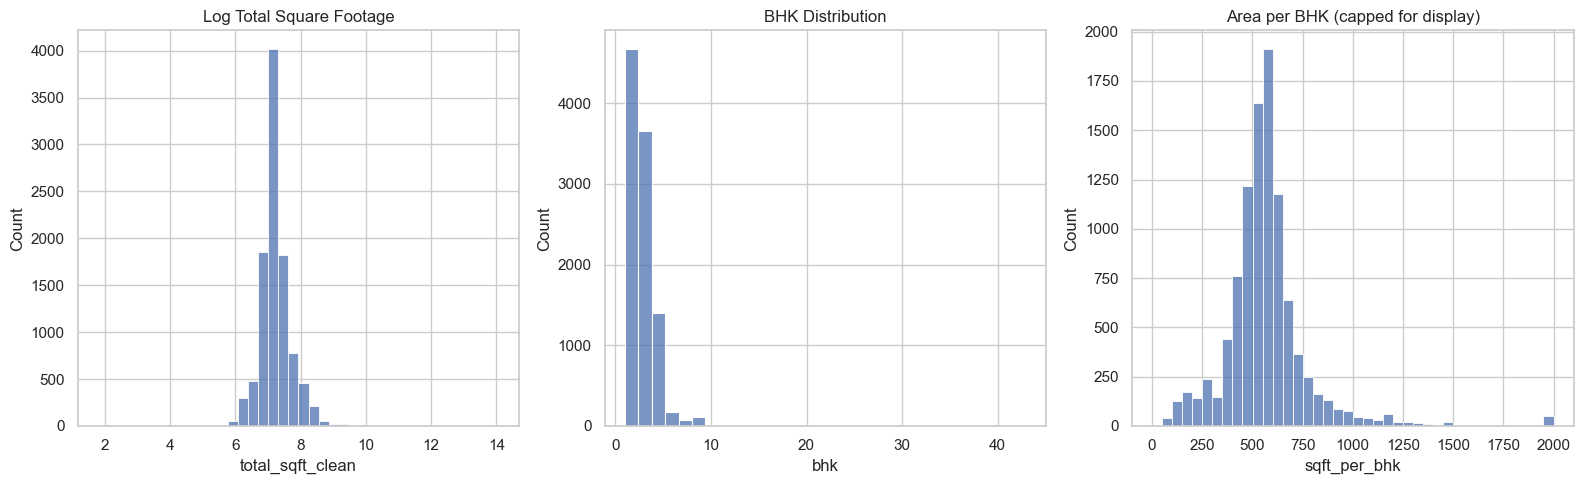

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.histplot(
    np.log1p(X_train["total_sqft_clean"]),
    bins=40, ax=axes[0]
)
axes[0].set_title("Log Total Square Footage")

sns.histplot(
    X_train["bhk"], bins=30, ax=axes[1]
)
axes[1].set_title("BHK Distribution")

sns.histplot(
    train_diagnostics["sqft_per_bhk"].clip(upper=2000),
    bins=40, ax=axes[2]
)
axes[2].set_title("Area per BHK (capped for display)")

plt.tight_layout()
plt.show()

In [32]:
# Create a separate copy of the training data
X_train_clean = X_train.copy()
y_train_clean = y_train.copy()

# Calculate area per bedroom
sqft_per_bhk = (
    X_train_clean["total_sqft_clean"] /
    X_train_clean["bhk"]
)

# Apply conservative plausibility filters
valid_mask = (
    (sqft_per_bhk >= 300) &
    (sqft_per_bhk <= 2000) &
    (X_train_clean["bhk"] <= 10) &
    (X_train_clean["bath"] <= 10)
)

X_train_clean = X_train_clean.loc[valid_mask].copy()
y_train_clean = y_train_clean.loc[valid_mask].copy()

print("Training records before cleaning:", len(X_train))
print("Training records after cleaning:", len(X_train_clean))
print("Records removed:", len(X_train) - len(X_train_clean))
print("Percentage removed:",
      round((1 - len(X_train_clean) / len(X_train)) * 100, 2), "%")

Training records before cleaning: 10088
Training records after cleaning: 9400
Records removed: 688
Percentage removed: 6.82 %


In [33]:
print("Cleaned training data shape:", X_train_clean.shape)

print("\nRemaining extreme values:")

display(
    X_train_clean[
        ["total_sqft_clean", "bhk", "bath"]
    ].describe().T
)

print("\nRemaining missing values:")
display(X_train_clean.isnull().sum())

Cleaned training data shape: (9400, 6)

Remaining extreme values:


,count,mean,std,min,25%,50%,75%,max
total_sqft_clean,9400.0,1564.341668,862.684443,300.0,1115.0,1300.0,1705.0,12000.0
bhk,9400.0,2.644149,0.947425,1.0,2.0,3.0,3.0,10.0
bath,9400.0,2.567447,1.054088,1.0,2.0,2.0,3.0,10.0



Remaining missing values:


area_type             0
location              0
total_sqft_clean      0
bhk                   0
bath                  0
balcony             343
dtype: int64

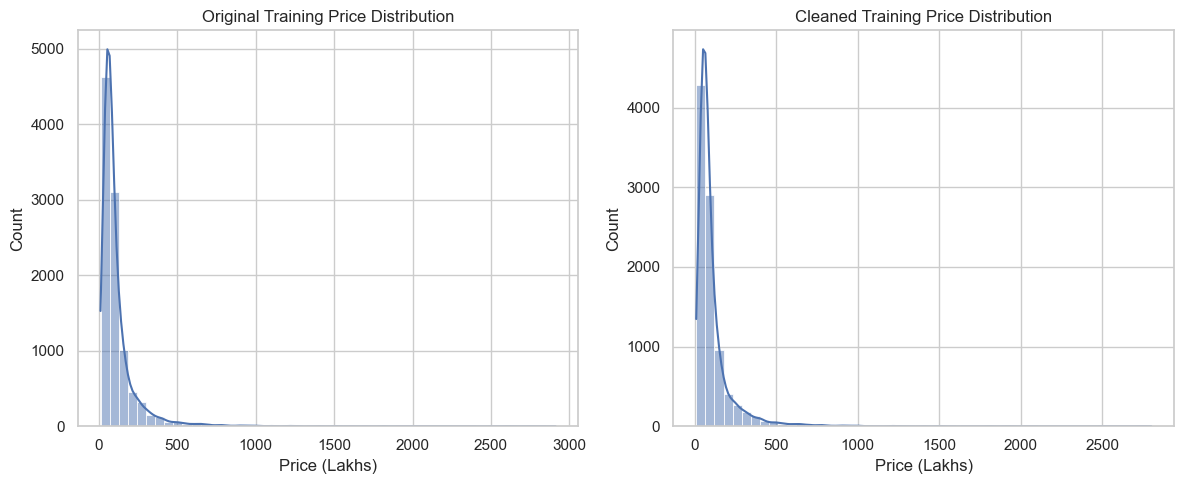

Original training mean: 114.77699048374306
Cleaned training mean: 111.03046702127658
Original training median: 73.0
Cleaned training median: 70.0


In [34]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(y_train, bins=50, kde=True)
plt.title("Original Training Price Distribution")
plt.xlabel("Price (Lakhs)")

plt.subplot(1, 2, 2)
sns.histplot(y_train_clean, bins=50, kde=True)
plt.title("Cleaned Training Price Distribution")
plt.xlabel("Price (Lakhs)")

plt.tight_layout()
plt.show()

print("Original training mean:", y_train.mean())
print("Cleaned training mean:", y_train_clean.mean())
print("Original training median:", y_train.median())
print("Cleaned training median:", y_train_clean.median())

In [35]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Model components imported successfully!")

Model components imported successfully!


In [36]:
numerical_features = [
    "total_sqft_clean",
    "bhk",
    "bath",
    "balcony"
]

categorical_features = [
    "area_type",
    "location"
]

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

print("\nNumber of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))

Numerical features: ['total_sqft_clean', 'bhk', 'bath', 'balcony']
Categorical features: ['area_type', 'location']

Number of numerical features: 4
Number of categorical features: 2


In [37]:
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

print("Numerical preprocessing pipeline created.")

Numerical preprocessing pipeline created.


In [38]:
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="infrequent_if_exist",
        min_frequency=5
    ))
])

print("Categorical preprocessing pipeline created.")

Categorical preprocessing pipeline created.


In [39]:
preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", numerical_pipeline, numerical_features),
        ("categorical", categorical_pipeline, categorical_features)
    ]
)

print("Complete preprocessing pipeline created!")

Complete preprocessing pipeline created!


In [40]:
X_train_processed = preprocessor.fit_transform(X_train_clean)

print("Original training shape:", X_train_clean.shape)
print("Processed training shape:", X_train_processed.shape)

print("\nProcessed data type:", type(X_train_processed))
print("Missing values in processed data:",
      np.isnan(X_train_processed.data).sum()
      if hasattr(X_train_processed, "data")
      else np.isnan(X_train_processed).sum())

Original training shape: (9400, 6)
Processed training shape: (9400, 354)

Processed data type: <class 'scipy.sparse._csr.csr_matrix'>
Missing values in processed data: 0


In [41]:
models = {
    "Dummy Regressor": DummyRegressor(strategy="mean"),

    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(alpha=10),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=20,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=RANDOM_STATE
    )
}

print("Models defined:")
for name in models:
    print("-", name)

Models defined:
- Dummy Regressor
- Linear Regression
- Ridge Regression
- Random Forest
- Gradient Boosting


In [42]:
def evaluate_model(model, X_train, y_train, X_test, y_test):

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    train_predictions = pipeline.predict(X_train)
    test_predictions = pipeline.predict(X_test)

    results = {
        "Train R2": r2_score(y_train, train_predictions),
        "Test R2": r2_score(y_test, test_predictions),
        "MAE": mean_absolute_error(y_test, test_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, test_predictions))
    }

    return pipeline, results

In [43]:
trained_models = {}
results = []

for name, model in models.items():

    print(f"Training {name}...")

    pipeline, metrics = evaluate_model(
        model,
        X_train_clean,
        y_train_clean,
        X_test,
        y_test
    )

    trained_models[name] = pipeline

    results.append({
        "Model": name,
        **metrics
    })

print("\nAll models trained successfully!")

Training Dummy Regressor...
Training Linear Regression...
Training Ridge Regression...
Training Random Forest...
Training Gradient Boosting...

All models trained successfully!


In [44]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Test R2",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Model,Train R2,Test R2,MAE,RMSE
0,Gradient Boosting,0.7642,0.5278,37.1808,102.2011
1,Random Forest,0.8431,0.5002,37.3657,105.1371
2,Dummy Regressor,0.0000,-0.0009,74.0981,148.7856
3,Linear Regression,0.6784,-2.2027,49.0422,266.1528
4,Ridge Regression,0.6568,-2.4380,49.0593,275.7584


In [45]:
best_model = trained_models["Gradient Boosting"]

y_pred = best_model.predict(X_test)

prediction_results = pd.DataFrame({
    "Actual Price": y_test,
    "Predicted Price": y_pred
})

prediction_results["Absolute Error"] = abs(
    prediction_results["Actual Price"] -
    prediction_results["Predicted Price"]
)

display(prediction_results.head(15))

,Actual Price,Predicted Price,Absolute Error
8450,103.00,87.656246,15.343754
11981,150.00,189.976522,39.976522
1965,50.00,76.071710,26.071710
8277,35.00,52.398719,17.398719
9777,50.00,68.057035,18.057035
8730,130.00,231.707737,101.707737
3359,64.00,68.057035,4.057035
1761,160.00,87.656246,72.343754
173,56.00,71.027263,15.027263
10430,56.70,66.343659,9.643659


In [46]:
display(
    prediction_results.sort_values(
        "Absolute Error",
        ascending=False
    ).head(20)
)

,Actual Price,Predicted Price,Absolute Error
13067,3600.0,527.062230,3072.937770
872,45.0,1345.726614,1300.726614
10488,200.0,1313.484602,1113.484602
7334,125.0,1179.612398,1054.612398
5469,450.0,1412.952148,962.952148
4799,390.0,1203.769663,813.769663
440,700.0,1446.834335,746.834335
8004,385.0,1112.397389,727.397389
5711,1150.0,480.030348,669.969652
8743,104.0,694.427806,590.427806


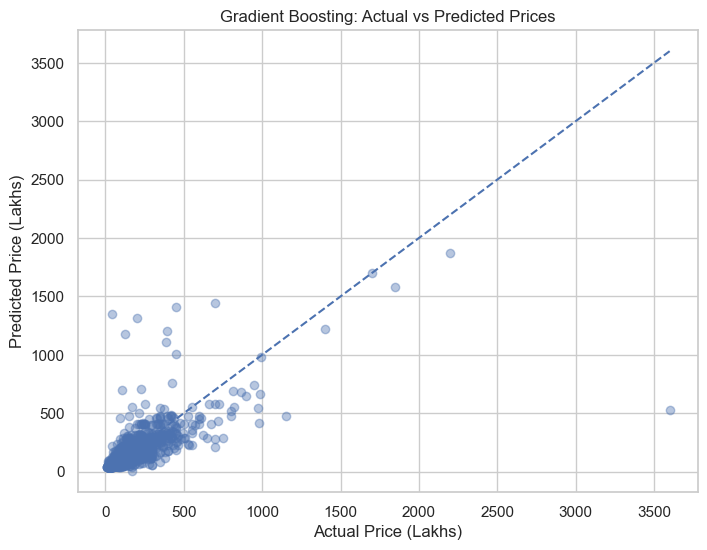

In [47]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.4)

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual Price (Lakhs)")
plt.ylabel("Predicted Price (Lakhs)")
plt.title("Gradient Boosting: Actual vs Predicted Prices")
plt.show()

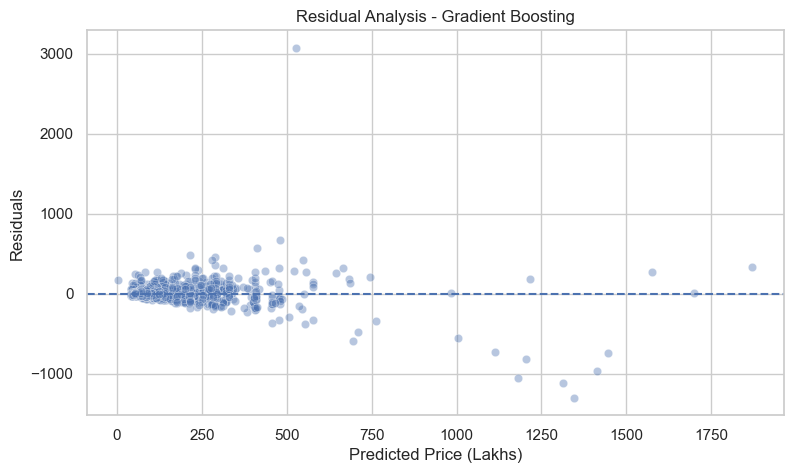

Mean residual: -1.4726040183104034
Residual standard deviation: 102.21078769226214


In [48]:
residuals = y_test - y_pred

plt.figure(figsize=(9, 5))

sns.scatterplot(
    x=y_pred,
    y=residuals,
    alpha=0.4
)

plt.axhline(0, linestyle="--")

plt.xlabel("Predicted Price (Lakhs)")
plt.ylabel("Residuals")
plt.title("Residual Analysis - Gradient Boosting")
plt.show()

print("Mean residual:", residuals.mean())
print("Residual standard deviation:", residuals.std())

In [49]:
model_df_clean = model_df.copy()

# Calculate square feet per bedroom
model_df_clean["sqft_per_bhk"] = (
    model_df_clean["total_sqft_clean"] /
    model_df_clean["bhk"]
)

# Apply consistent property-level filtering
valid_mask = (
    (model_df_clean["sqft_per_bhk"] >= 300) &
    (model_df_clean["sqft_per_bhk"] <= 2000) &
    (model_df_clean["bhk"] <= 10) &
    (
        model_df_clean["bath"].isna() |
        (model_df_clean["bath"] <= 10)
    )
)

model_df_clean = model_df_clean.loc[valid_mask].copy()

model_df_clean.drop(
    columns=["sqft_per_bhk"],
    inplace=True
)

print("Original records:", len(model_df))
print("Cleaned records:", len(model_df_clean))
print("Removed records:", len(model_df) - len(model_df_clean))

display(model_df_clean.describe())

Original records: 12611
Cleaned records: 11811
Removed records: 800


,total_sqft_clean,bhk,bath,balcony,price,price_per_sqft
count,11811.000000,11811.000000,11755.000000,11325.000000,11811.000000,11811.000000
mean,1569.859786,2.658369,2.570991,1.587991,111.416059,6373.683000
std,867.700639,0.963540,1.063154,0.816401,140.461016,4198.469595
min,300.000000,1.000000,1.000000,0.000000,9.000000,500.000000
25%,1116.000000,2.000000,2.000000,1.000000,50.000000,4255.319149
50%,1306.000000,3.000000,2.000000,2.000000,70.000000,5337.690632
75%,1711.000000,3.000000,3.000000,2.000000,120.000000,6987.764723
max,12000.000000,10.000000,10.000000,3.000000,2800.000000,176470.588235


In [50]:
X = model_df_clean[
    [
        "area_type",
        "location",
        "total_sqft_clean",
        "bhk",
        "bath",
        "balcony"
    ]
].copy()

y = model_df_clean["price"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining target mean:", y_train.mean())
print("Testing target mean:", y_test.mean())

Training records: 9448
Testing records: 2363

Training target mean: 111.70168077900084
Testing target mean: 110.27405628438426


In [51]:
from sklearn.model_selection import KFold, cross_validate

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "r2": "r2",
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error"
}

print("5-Fold Cross-validation configured successfully.")

5-Fold Cross-validation configured successfully.


In [52]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

models = {
    "Dummy Regressor": DummyRegressor(strategy="mean"),

    "Ridge Regression": Ridge(alpha=10),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=20,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42
    )
}

In [53]:
cv_results = []

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    print(f"Evaluating {name}...")

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean R2": scores["test_r2"].mean(),
        "Std R2": scores["test_r2"].std(),
        "Mean MAE": -scores["test_mae"].mean(),
        "Mean RMSE": -scores["test_rmse"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df = cv_results_df.sort_values(
    by="Mean R2",
    ascending=False
)

display(cv_results_df.round(4))

Evaluating Dummy Regressor...
Evaluating Ridge Regression...
Evaluating Random Forest...
Evaluating Gradient Boosting...


,Model,Mean R2,Std R2,Mean MAE,Mean RMSE
3,Gradient Boosting,0.6629,0.0549,33.7971,79.5497
1,Ridge Regression,0.6593,0.0234,36.3925,79.5867
2,Random Forest,0.6341,0.0644,32.9888,83.0328
0,Dummy Regressor,-0.0010,0.0008,73.7357,136.4332


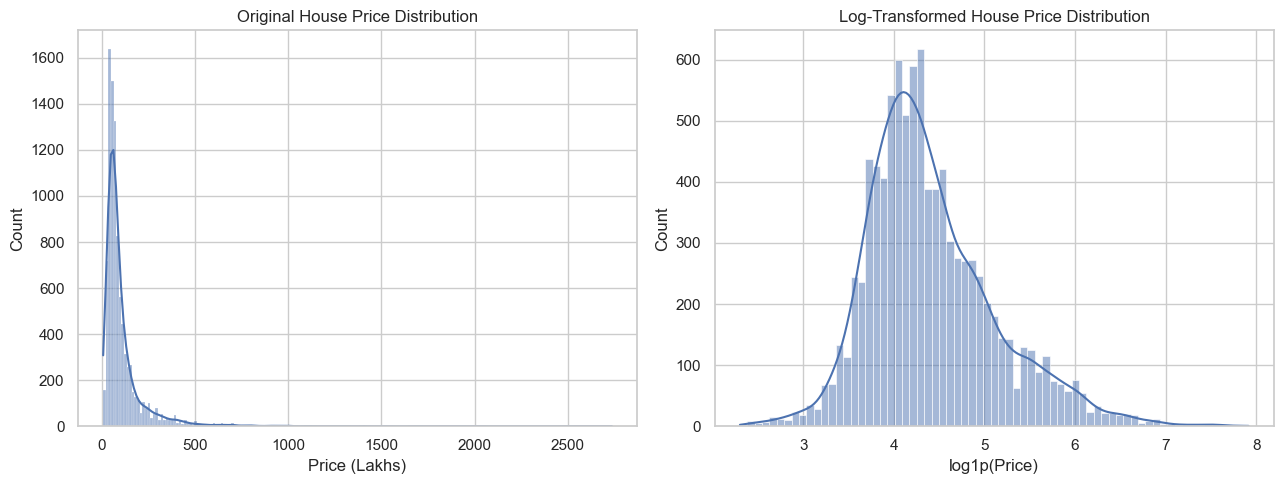

Original skewness: 6.387506724135546
Log-transformed skewness: 0.8518569958830546


In [54]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(y_train, kde=True, ax=axes[0])
axes[0].set_title("Original House Price Distribution")
axes[0].set_xlabel("Price (Lakhs)")

sns.histplot(np.log1p(y_train), kde=True, ax=axes[1])
axes[1].set_title("Log-Transformed House Price Distribution")
axes[1].set_xlabel("log1p(Price)")

plt.tight_layout()
plt.show()

print("Original skewness:", y_train.skew())
print("Log-transformed skewness:", np.log1p(y_train).skew())

In [55]:
from sklearn.compose import TransformedTargetRegressor

In [56]:
log_models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=20,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42
    )
}

In [57]:
log_cv_results = []

for name, model in log_models.items():

    transformed_model = TransformedTargetRegressor(
        regressor=Pipeline(steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]),
        func=np.log1p,
        inverse_func=np.expm1
    )

    print(f"Evaluating log-transformed {name}...")

    scores = cross_validate(
        transformed_model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    log_cv_results.append({
        "Model": name + " (Log Target)",
        "Mean R2": scores["test_r2"].mean(),
        "Std R2": scores["test_r2"].std(),
        "Mean MAE": -scores["test_mae"].mean(),
        "Mean RMSE": -scores["test_rmse"].mean()
    })

log_cv_results_df = pd.DataFrame(log_cv_results)

display(log_cv_results_df.round(4))

Evaluating log-transformed Random Forest...
Evaluating log-transformed Gradient Boosting...


,Model,Mean R2,Std R2,Mean MAE,Mean RMSE
0,Random Forest (Log Target),0.6176,0.0675,32.0795,84.9451
1,Gradient Boosting (Log Target),0.6369,0.0509,32.3642,82.5819


In [58]:
from sklearn.model_selection import RandomizedSearchCV

gb_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(random_state=42))
])

In [59]:
param_distributions = {
    "model__n_estimators": [100, 200, 300, 400, 500],

    "model__learning_rate": [0.01, 0.03, 0.05, 0.07, 0.1],

    "model__max_depth": [2, 3, 4, 5],

    "model__min_samples_split": [2, 5, 10, 15],

    "model__min_samples_leaf": [1, 2, 4, 6],

    "model__subsample": [0.7, 0.8, 0.9, 1.0],

    "model__max_features": [None, "sqrt", "log2"]
}

In [60]:
gb_search = RandomizedSearchCV(
    estimator=gb_pipeline,
    param_distributions=param_distributions,
    n_iter=40,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

gb_search.fit(X_train, y_train)

print("Best parameters:")
print(gb_search.best_params_)

print("\nBest cross-validation RMSE:")
print(-gb_search.best_score_)

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best parameters:
{'model__subsample': 0.9, 'model__n_estimators': 500, 'model__min_samples_split': 15, 'model__min_samples_leaf': 4, 'model__max_features': 'log2', 'model__max_depth': 5, 'model__learning_rate': 0.1}

Best cross-validation RMSE:
78.5340969675448


In [61]:
gb_search_results = pd.DataFrame(gb_search.cv_results_)

gb_search_results = gb_search_results[
    [
        "rank_test_score",
        "mean_test_score",
        "std_test_score",
        "params"
    ]
].sort_values("rank_test_score")

gb_search_results["mean_test_RMSE"] = (
    -gb_search_results["mean_test_score"]
)

display(
    gb_search_results[
        [
            "rank_test_score",
            "mean_test_RMSE",
            "std_test_score",
            "params"
        ]
    ].head(10)
)

,rank_test_score,mean_test_RMSE,std_test_score,params
25,1,78.534097,17.121458,"{'model__subsample': 0.9, 'model__n_estimators..."
20,2,79.351442,18.050736,"{'model__subsample': 0.9, 'model__n_estimators..."
35,3,79.367768,19.515902,"{'model__subsample': 1.0, 'model__n_estimators..."
38,4,79.677996,14.230693,"{'model__subsample': 0.8, 'model__n_estimators..."
0,5,79.787712,14.005836,"{'model__subsample': 1.0, 'model__n_estimators..."
8,6,80.047785,19.094125,"{'model__subsample': 1.0, 'model__n_estimators..."
22,7,80.358910,19.747939,"{'model__subsample': 1.0, 'model__n_estimators..."
29,8,80.427553,17.127699,"{'model__subsample': 0.7, 'model__n_estimators..."
33,9,80.442944,20.752181,"{'model__subsample': 0.9, 'model__n_estimators..."
6,10,80.782966,15.891638,"{'model__subsample': 0.9, 'model__n_estimators..."


In [62]:
best_gb_model = gb_search.best_estimator_

print("Best Gradient Boosting model retrieved.")
print(best_gb_model)

Best Gradient Boosting model retrieved.
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['total_sqft_clean', 'bhk',
                                                   'bath', 'balcony']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                       

In [63]:
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ))
])

rf_param_distributions = {
    "model__n_estimators": [100, 200, 300, 400],

    "model__max_depth": [10, 15, 20, 25, None],

    "model__min_samples_split": [2, 5, 10],

    "model__min_samples_leaf": [1, 2, 4],

    "model__max_features": [0.7, 0.8, 1.0]
}

In [64]:
rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_param_distributions,
    n_iter=30,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train, y_train)

print("Best Random Forest parameters:")
print(rf_search.best_params_)
 
print("\nBest cross-validation RMSE:")
print(-rf_search.best_score_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Random Forest parameters:
{'model__n_estimators': 400, 'model__min_samples_split': 10, 'model__min_samples_leaf': 1, 'model__max_features': 0.8, 'model__max_depth': None}

Best cross-validation RMSE:
79.67881316645006


In [68]:
tuned_comparison = pd.DataFrame([
    {
        "Model": "Tuned Gradient Boosting",
        "CV RMSE": -gb_search.best_score_,
        "Best Parameters": gb_search.best_params_
    },
    {
        "Model": "Tuned Random Forest",
        "CV RMSE": -rf_search.best_score_,
        "Best Parameters": rf_search.best_params_
    }
])

display(tuned_comparison)

,Model,CV RMSE,Best Parameters
0,Tuned Gradient Boosting,78.534097,"{'model__subsample': 0.9, 'model__n_estimators..."
1,Tuned Random Forest,79.678813,"{'model__n_estimators': 400, 'model__min_sampl..."


In [66]:
print("Gradient Boosting CV RMSE:",
      round(-gb_search.best_score_, 4))

print("Random Forest CV RMSE:",
      round(-rf_search.best_score_, 4))

if gb_search.best_score_ > rf_search.best_score_:
    print("\nBest candidate: Gradient Boosting")
else:
    print("\nBest candidate: Random Forest")

Gradient Boosting CV RMSE: 78.5341
Random Forest CV RMSE: 79.6788

Best candidate: Gradient Boosting


In [67]:
if gb_search.best_score_ > rf_search.best_score_:
    final_candidate = gb_search.best_estimator_
    final_model_name = "Gradient Boosting"
else:
    final_candidate = rf_search.best_estimator_
    final_model_name = "Random Forest"

print("Selected model:", final_model_name)

Selected model: Gradient Boosting


In [83]:
final_model = gb_search.best_estimator_

final_model.fit(X_train, y_train)

print("Final Gradient Boosting model trained successfully.")

Final Gradient Boosting model trained successfully.


In [84]:
y_pred_final = final_model.predict(X_test)

print("Predictions generated successfully.")

prediction_df = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred_final
})

prediction_df["Absolute Error"] = abs(
    prediction_df["Actual Price"] -
    prediction_df["Predicted Price"]
)

display(prediction_df.head(15))

Predictions generated successfully.


,Actual Price,Predicted Price,Absolute Error
0,99.00,56.774118,42.225882
1,64.80,47.277150,17.522850
2,133.00,159.031020,26.031020
3,30.00,55.603855,25.603855
4,158.00,188.116185,30.116185
5,75.00,60.331582,14.668418
6,67.75,132.309555,64.559555
7,46.00,60.106127,14.106127
8,45.00,54.804012,9.804012
9,46.00,54.874510,8.874510


In [85]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

final_r2 = r2_score(y_test, y_pred_final)

final_mae = mean_absolute_error(
    y_test, y_pred_final
)

final_mse = mean_squared_error(
    y_test, y_pred_final
)

final_rmse = np.sqrt(final_mse)

print("FINAL MODEL PERFORMANCE")
print("-----------------------")
print("Model:", final_model_name)
print("R2 Score:", round(final_r2, 4))
print("MAE:", round(final_mae, 4), "Lakhs")
print("MSE:", round(final_mse, 4))
print("RMSE:", round(final_rmse, 4), "Lakhs")

FINAL MODEL PERFORMANCE
-----------------------
Model: Gradient Boosting
R2 Score: 0.5853
MAE: 34.4603 Lakhs
MSE: 9447.685
RMSE: 97.1992 Lakhs


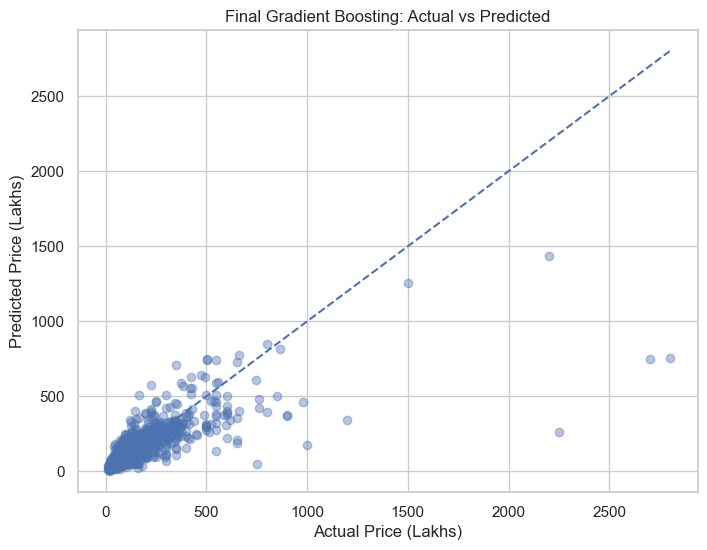

In [86]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_final,
    alpha=0.4
)

minimum = min(y_test.min(), y_pred_final.min())
maximum = max(y_test.max(), y_pred_final.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual Price (Lakhs)")
plt.ylabel("Predicted Price (Lakhs)")
plt.title("Final Gradient Boosting: Actual vs Predicted")
plt.show()

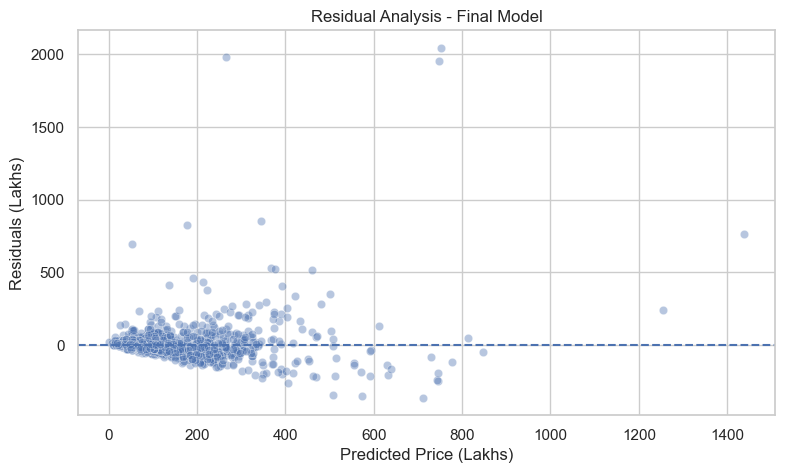

Mean residual: 3.5022857810797503
Residual standard deviation: 97.15664525165921


In [87]:
final_residuals = y_test - y_pred_final

plt.figure(figsize=(9, 5))

sns.scatterplot(
    x=y_pred_final,
    y=final_residuals,
    alpha=0.4
)

plt.axhline(0, linestyle="--")

plt.xlabel("Predicted Price (Lakhs)")
plt.ylabel("Residuals (Lakhs)")
plt.title("Residual Analysis - Final Model")

plt.show()

print("Mean residual:", final_residuals.mean())
print("Residual standard deviation:", final_residuals.std())

In [88]:
prediction_df["Signed Error"] = (
    prediction_df["Predicted Price"] -
    prediction_df["Actual Price"]
)

largest_errors = prediction_df.sort_values(
    by="Absolute Error",
    ascending=False
)

display(largest_errors.head(20))

,Actual Price,Predicted Price,Absolute Error,Signed Error
297,2800.0,753.340504,2046.659496,-2046.659496
688,2250.0,265.955831,1984.044169,-1984.044169
528,2700.0,747.010148,1952.989852,-1952.989852
1181,1200.0,345.520989,854.479011,-854.479011
1283,1000.0,176.583072,823.416928,-823.416928
2284,2200.0,1437.023041,762.976959,-762.976959
611,750.0,51.899932,698.100068,-698.100068
1365,900.0,367.525047,532.474953,-532.474953
2211,899.0,376.648278,522.351722,-522.351722
2173,980.0,460.824074,519.175926,-519.175926


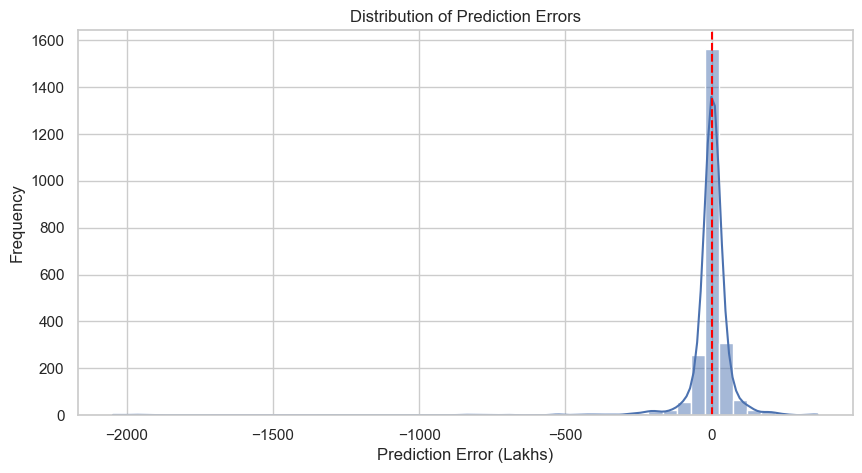

In [89]:
plt.figure(figsize=(10, 5))

sns.histplot(
    prediction_df["Signed Error"],
    bins=50,
    kde=True
)

plt.axvline(0, color="red", linestyle="--")

plt.title("Distribution of Prediction Errors")
plt.xlabel("Prediction Error (Lakhs)")
plt.ylabel("Frequency")

plt.show()

In [90]:
error_analysis = X_test.loc[y_test.index].copy()

error_analysis["Actual Price"] = y_test
error_analysis["Predicted Price"] = y_pred_final

error_analysis["Absolute Error"] = abs(
    error_analysis["Actual Price"] -
    error_analysis["Predicted Price"]
)

error_analysis["Signed Error"] = (
    error_analysis["Predicted Price"] -
    error_analysis["Actual Price"]
)

largest_errors_detailed = error_analysis.sort_values(
    by="Absolute Error",
    ascending=False
)

display(largest_errors_detailed.head(20))

,area_type,location,total_sqft_clean,bhk,bath,balcony,Actual Price,Predicted Price,Absolute Error,Signed Error
13200,Plot Area,Defence Colony,8000.0,6.0,6.0,3.0,2800.0,753.340504,2046.659496,-2046.659496
6421,Plot Area,Bommenahalli,2940.0,4.0,3.0,2.0,2250.0,265.955831,1984.044169,-1984.044169
3180,Super built-up Area,Shanthala Nagar,8321.0,5.0,5.0,3.0,2700.0,747.010148,1952.989852,-1952.989852
1299,Plot Area,Chamrajpet,4050.0,9.0,7.0,1.0,1200.0,345.520989,854.479011,-854.479011
9737,Built-up Area,Ngef Layout,2100.0,4.0,3.0,1.0,1000.0,176.583072,823.416928,-823.416928
408,Super built-up Area,Rajaji Nagar,12000.0,7.0,6.0,3.0,2200.0,1437.023041,762.976959,-762.976959
7657,Built-up Area,Raghuvanahalli,425.0,1.0,1.0,1.0,750.0,51.899932,698.100068,-698.100068
1678,Plot Area,Whitefield,3250.0,5.0,5.0,3.0,900.0,367.525047,532.474953,-532.474953
5348,Plot Area,Yelahanka New Town,4000.0,4.0,2.0,1.0,899.0,376.648278,522.351722,-522.351722
7447,Super built-up Area,Rest House Road,4900.0,5.0,5.0,NaN,980.0,460.824074,519.175926,-519.175926


In [91]:
feature_names = (
    final_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = (
    final_model
    .named_steps["model"]
    .feature_importances_
)

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance_df.head(25))

,Feature,Importance
0,numerical__total_sqft_clean,0.416235
1,numerical__bhk,0.147425
2,numerical__bath,0.118976
290,categorical__location_Sadashiva Nagar,0.042037
6,categorical__area_type_Plot Area,0.037683
350,categorical__location_Yemlur,0.028539
237,categorical__location_Malleshwaram,0.023657
106,categorical__location_Cunningham Road,0.022427
3,numerical__balcony,0.016582
279,categorical__location_Rajaji Nagar,0.015789


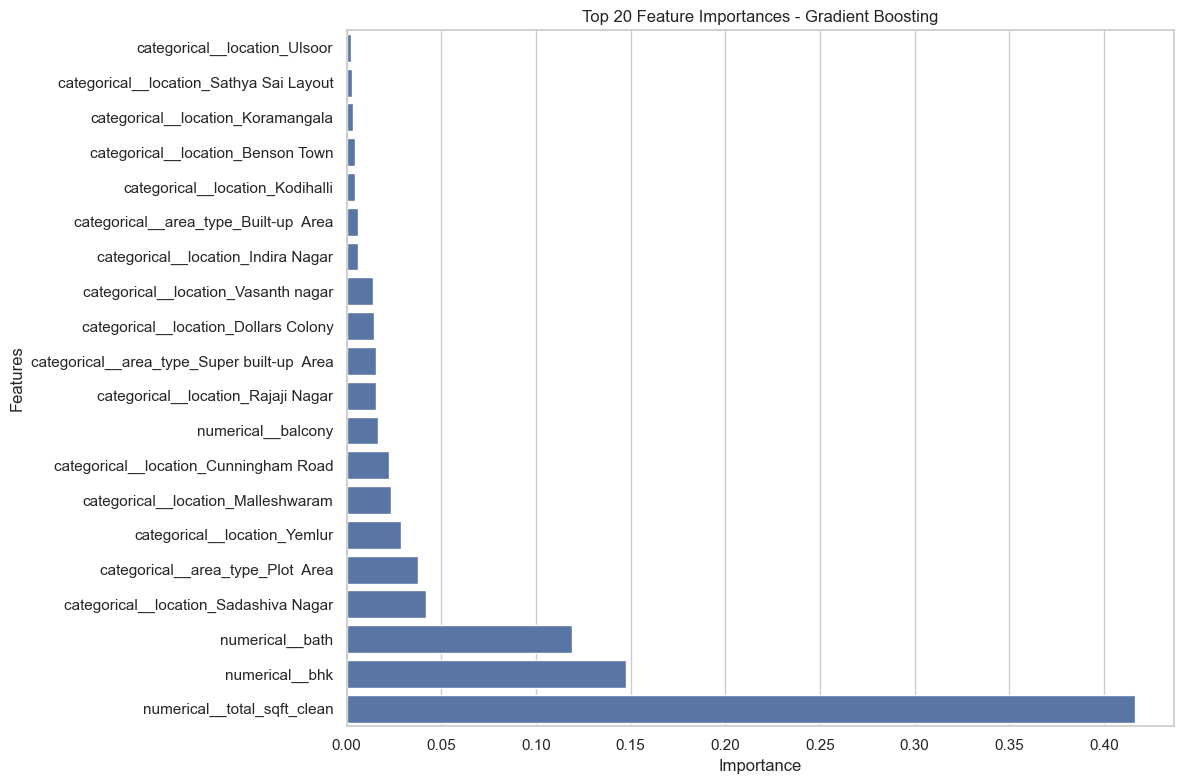

In [92]:
plt.figure(figsize=(12, 8))

top_features = feature_importance_df.head(20).sort_values(
    by="Importance"
)

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 20 Feature Importances - Gradient Boosting")
plt.xlabel("Importance")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [93]:
feature_importance_df["Feature Group"] = (
    feature_importance_df["Feature"]
    .str.replace("numerical__", "", regex=False)
    .str.replace("categorical__", "", regex=False)
    .str.split("_")
    .str[0]
)

# Correctly group numerical features
feature_importance_df.loc[
    feature_importance_df["Feature"].str.startswith("numerical__"),
    "Feature Group"
] = "Numerical Features"

# Group categorical features
feature_importance_df.loc[
    feature_importance_df["Feature"].str.startswith("categorical__location_"),
    "Feature Group"
] = "Location"

feature_importance_df.loc[
    feature_importance_df["Feature"].str.startswith("categorical__area_type_"),
    "Feature Group"
] = "Area Type"

grouped_importance = (
    feature_importance_df
    .groupby("Feature Group")["Importance"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

grouped_importance["Percentage"] = (
    grouped_importance["Importance"] * 100
)

display(grouped_importance)

,Feature Group,Importance,Percentage
0,Numerical Features,0.699218,69.921813
1,Location,0.241682,24.168224
2,Area Type,0.059100,5.909964


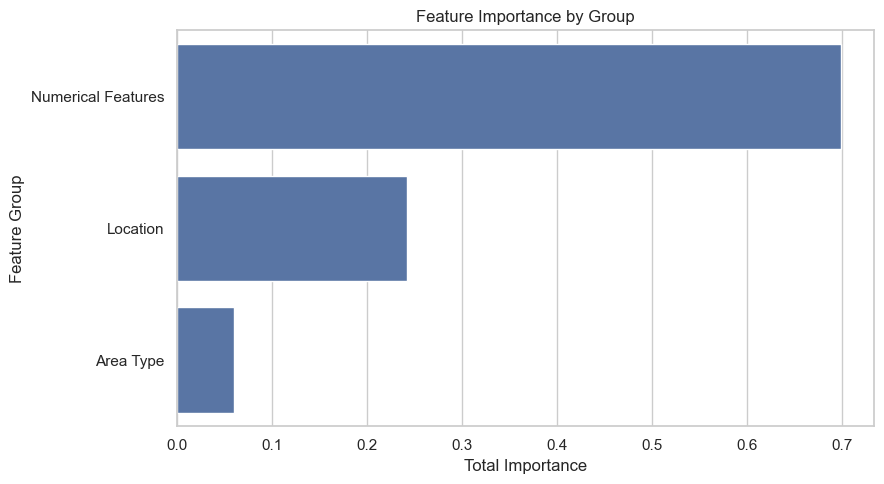

In [94]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=grouped_importance,
    x="Importance",
    y="Feature Group"
)

plt.title("Feature Importance by Group")
plt.xlabel("Total Importance")
plt.ylabel("Feature Group")

plt.tight_layout()
plt.show()

In [95]:
import joblib

model_filename = "bengaluru_house_price_model.joblib"

joblib.dump(final_model, model_filename)

print("Final model saved successfully!")
print("Filename:", model_filename)

Final model saved successfully!
Filename: bengaluru_house_price_model.joblib


In [96]:
loaded_model = joblib.load(
    "bengaluru_house_price_model.joblib"
)

print("Model loaded successfully!")

Model loaded successfully!


In [97]:
new_property = pd.DataFrame([{
    "area_type": "Super built-up Area",
    "location": "Whitefield",
    "total_sqft_clean": 1200,
    "bhk": 2,
    "bath": 2,
    "balcony": 1
}])

predicted_price = loaded_model.predict(new_property)

print(
    f"Estimated House Price: ₹{predicted_price[0]:.2f} Lakhs"
)

Estimated House Price: ₹54.89 Lakhs


In [98]:
model_results = results_df.copy()

model_results.to_csv(
    "model_results.csv",
    index=False
)

print("Model performance results exported successfully.")

Model performance results exported successfully.


In [99]:
import pandas as pd

hyperparameter_rows = []

for model_name, model in models.items():

    if hasattr(model, "best_estimator_"):
        model = model.best_estimator_

    if hasattr(model, "get_params"):
        params = model.get_params()

        for parameter, value in params.items():
            hyperparameter_rows.append({
                "Model": model_name,
                "Parameter": parameter,
                "Value": str(value)
            })

hyperparameters_df = pd.DataFrame(hyperparameter_rows)

hyperparameters_df.to_csv(
    "model_hyperparameters.csv",
    index=False
)

print("Hyperparameter configurations exported successfully.")

Hyperparameter configurations exported successfully.


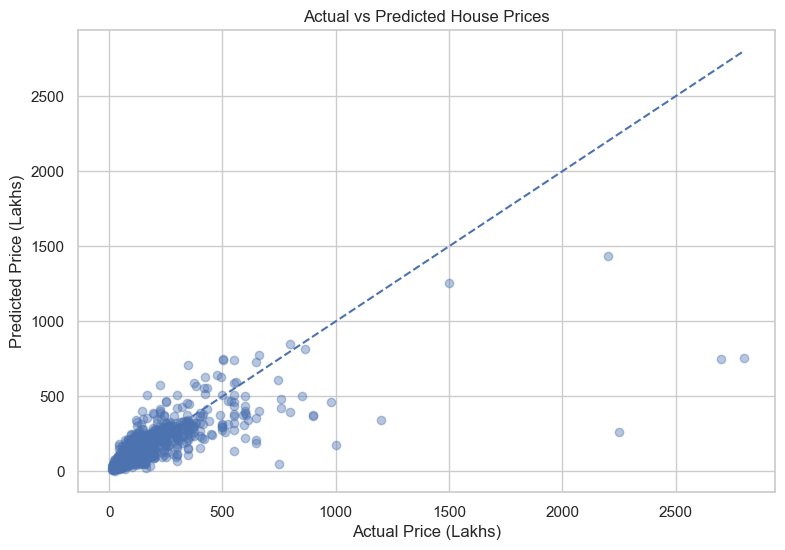

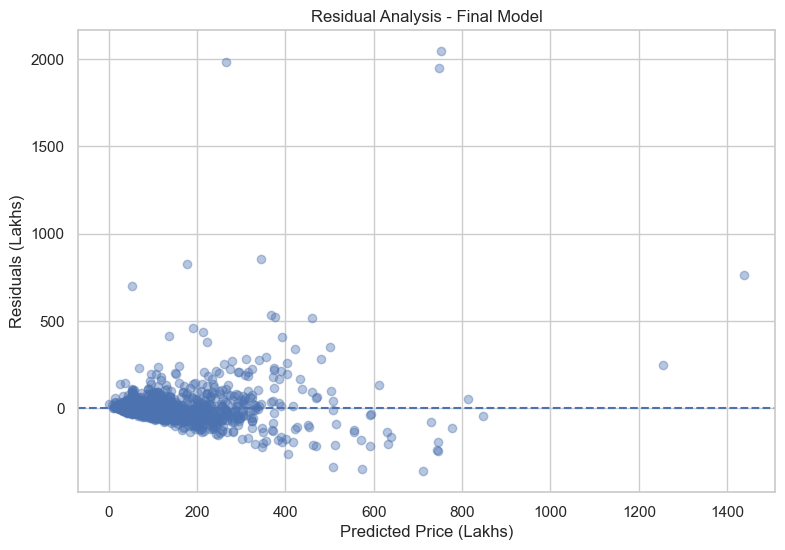

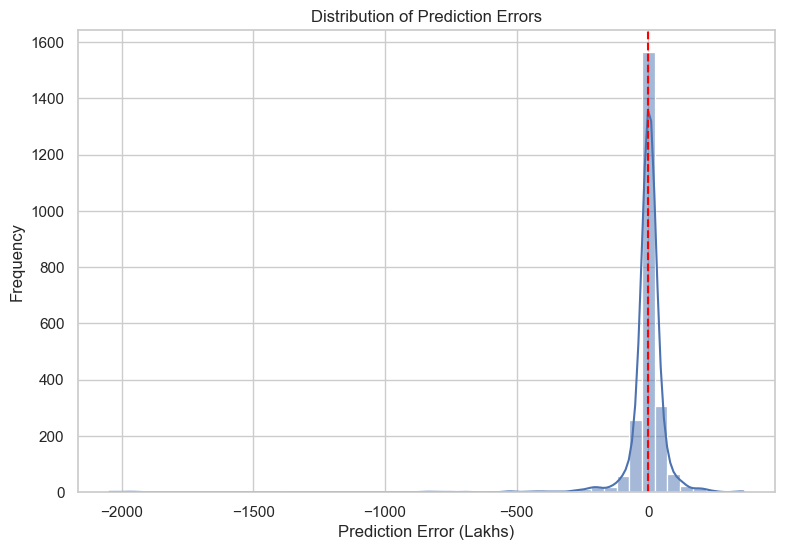

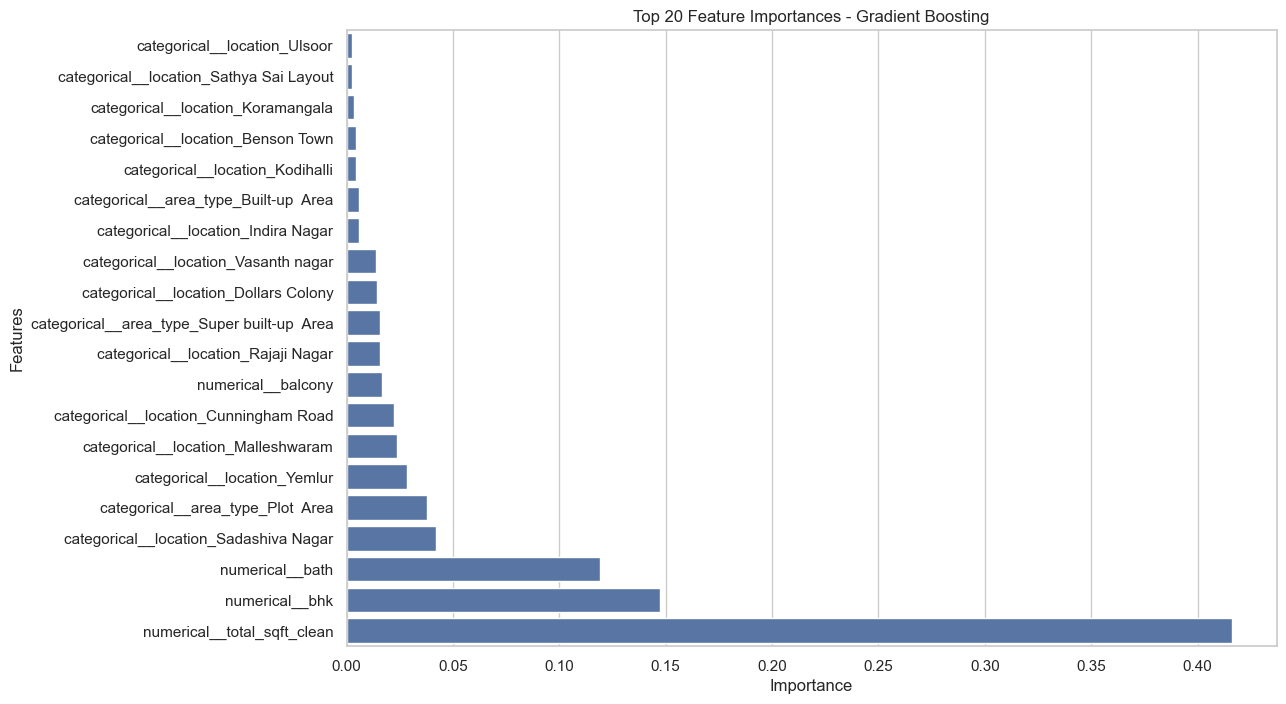

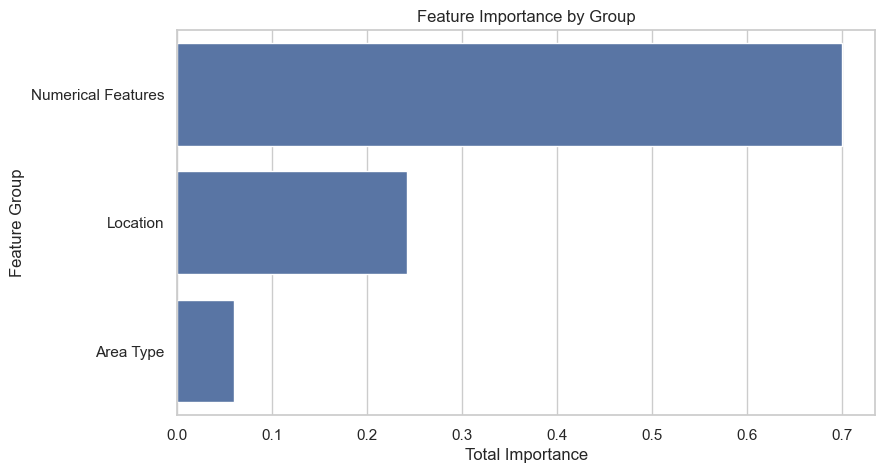


All figures exported successfully!
Output directory: figures/
Caption file: figure_captions.csv


,Figure Number,Filename,Caption
0,Figure 1,figure_01_actual_vs_predicted.png,Actual versus predicted house prices using the...
1,Figure 2,figure_02_residual_analysis.png,Residuals versus predicted house prices for th...
2,Figure 3,figure_03_prediction_error_distribution.png,"Distribution of prediction errors, showing the..."
3,Figure 4,figure_04_top_20_feature_importance.png,Top 20 features influencing the predictions of...
4,Figure 5,figure_05_grouped_feature_importance.png,"Relative importance of numerical features, loc..."


In [100]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Create figures directory
os.makedirs("figures", exist_ok=True)

figure_captions = []

def save_figure(fig, number, filename, caption):
    filepath = os.path.join("figures", filename)

    fig.savefig(
        filepath,
        dpi=300,
        bbox_inches="tight"
    )

    figure_captions.append({
        "Figure Number": f"Figure {number}",
        "Filename": filename,
        "Caption": caption
    })

    plt.show()
    plt.close(fig)

# --------------------------------------------------
# FIGURE 1: ACTUAL VS PREDICTED
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    y_test,
    y_pred_final,
    alpha=0.4
)

min_value = min(y_test.min(), y_pred_final.min())
max_value = max(y_test.max(), y_pred_final.max())

ax.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

ax.set_title("Actual vs Predicted House Prices")
ax.set_xlabel("Actual Price (Lakhs)")
ax.set_ylabel("Predicted Price (Lakhs)")

save_figure(
    fig,
    1,
    "figure_01_actual_vs_predicted.png",
    "Actual versus predicted house prices using the final Gradient Boosting model."
)


# --------------------------------------------------
# FIGURE 2: RESIDUAL ANALYSIS
# --------------------------------------------------

residuals = (
    np.asarray(y_test) -
    np.asarray(y_pred_final)
)

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    y_pred_final,
    residuals,
    alpha=0.4
)

ax.axhline(
    y=0,
    linestyle="--"
)

ax.set_title("Residual Analysis - Final Model")
ax.set_xlabel("Predicted Price (Lakhs)")
ax.set_ylabel("Residuals (Lakhs)")

save_figure(
    fig,
    2,
    "figure_02_residual_analysis.png",
    "Residuals versus predicted house prices for the final Gradient Boosting model."
)


# --------------------------------------------------
# FIGURE 3: PREDICTION ERROR DISTRIBUTION
# --------------------------------------------------

prediction_errors = (
    np.asarray(y_pred_final) -
    np.asarray(y_test)
)

fig, ax = plt.subplots(figsize=(9, 6))

sns.histplot(
    prediction_errors,
    bins=50,
    kde=True,
    ax=ax
)

ax.axvline(
    x=0,
    color="red",
    linestyle="--"
)

ax.set_title("Distribution of Prediction Errors")
ax.set_xlabel("Prediction Error (Lakhs)")
ax.set_ylabel("Frequency")

save_figure(
    fig,
    3,
    "figure_03_prediction_error_distribution.png",
    "Distribution of prediction errors, showing the spread and direction of model errors."
)


# --------------------------------------------------
# FIGURE 4: TOP 20 FEATURE IMPORTANCE
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 8))

top_features = (
    feature_importance_df
    .head(20)
    .sort_values("Importance")
)

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature",
    ax=ax
)

ax.set_title("Top 20 Feature Importances - Gradient Boosting")
ax.set_xlabel("Importance")
ax.set_ylabel("Features")

save_figure(
    fig,
    4,
    "figure_04_top_20_feature_importance.png",
    "Top 20 features influencing the predictions of the Gradient Boosting model."
)


# --------------------------------------------------
# FIGURE 5: GROUPED FEATURE IMPORTANCE
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=grouped_importance,
    x="Importance",
    y="Feature Group",
    ax=ax
)

ax.set_title("Feature Importance by Group")
ax.set_xlabel("Total Importance")
ax.set_ylabel("Feature Group")

save_figure(
    fig,
    5,
    "figure_05_grouped_feature_importance.png",
    "Relative importance of numerical features, location and area type."
)


# --------------------------------------------------
# EXPORT FIGURE CAPTIONS
# --------------------------------------------------

captions_df = pd.DataFrame(figure_captions)

captions_df.to_csv(
    "figure_captions.csv",
    index=False
)

print("\nAll figures exported successfully!")
print("Output directory: figures/")
print("Caption file: figure_captions.csv")

display(captions_df)